## Project 1: Predicting Term Deposit Subscription (Bank Marketing)
### MUGANGA CHARLES B35391

DSC8307 Data Mining, Modeling and Analytics. Advent 2026 Assignment.

### What this notebook does

A Portuguese bank phoned customers to sell them a term deposit. Most people said no. The bank would like a model that tells it, before dialling, which customers are worth calling. This notebook works through the problem in the order the assignment asks:

1. Exploring the data, writing a short report on what it contains and what is wrong with it, preparing it with a reason for every step, and setting a majority class baseline.
2. Building three candidate approaches, comparing them with several kinds of evidence, and ranking them.
3. Recommending a decision threshold and explaining the trade off between wasted calls and missed subscribers.

Everything runs from top to bottom with the packages in `requirements.txt`. The data file is read from the `data` folder in this repository. A single random seed is used throughout so the numbers in the text match the numbers in the outputs.

In [ ]:
# Here I am importing the libraries I need for handling the data, modelling and plotting
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_val_predict, TimeSeriesSplit)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             accuracy_score, precision_score, recall_score, f1_score,
                             precision_recall_curve, roc_curve)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)

# I fixed one random seed here so that every split, fold and model gives the same answer each time I run this
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## Part 1. Understanding the data

### 1.1 Loading the file

The file uses semicolons as separators. According to the accompanying README there are 20 inputs and one target, `y`, which records whether the customer subscribed. The data comes from the study by Moro, Cortez and Rita (2014) and covers calls made between May 2008 and November 2010.

In [2]:
# Loading the data (the file uses semicolons as separators) and taking a first look
raw = pd.read_csv("data/bank-additional-full.csv", sep=";")
print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
# Checking the column types and looking for empty cells
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

There are 41,188 calls and no blank cells at all. That looks tidy, but the README warns that missing answers were written as the word `unknown` instead of being left empty, so we need to look for them explicitly.

### 1.2 How unbalanced is the target?

     count   share
y                 
no   36548  0.8873
yes   4640  0.1127


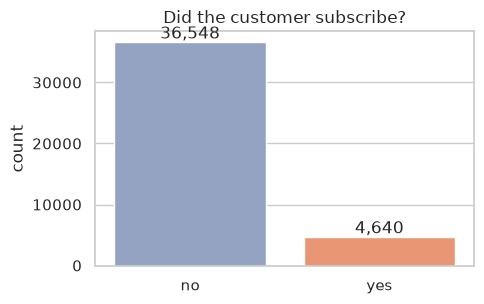

In [4]:
# Looking at how unbalanced the target is
target_share = raw["y"].value_counts().to_frame("count")
target_share["share"] = (target_share["count"] / len(raw)).round(4)
print(target_share)

fig, ax = plt.subplots(figsize=(5, 3.2))
sns.countplot(x="y", data=raw, ax=ax, palette=["#8da0cb", "#fc8d62"])
ax.set_title("Did the customer subscribe?")
ax.set_xlabel("")
for p in ax.patches:
    ax.annotate(f"{p.get_height():,.0f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout(); plt.show()

Only about 11.3 percent of calls ended in a subscription. This one fact shapes the whole analysis. A model that always says "no" is already right 88.7 percent of the time, so accuracy is a poor yardstick here. I will lean mainly on the area under the precision and recall curve (PR AUC, also called average precision), because it focuses on how well the rare positive cases are found and is more informative than ROC AUC when one class is small (Saito and Rehmsmeier, 2015). ROC AUC and the Brier score are reported alongside it.

### 1.3 Hidden missing values and duplicates

In [5]:
# I am counting the hidden missing values, since the README says they were stored as the word "unknown"
cat_cols = raw.select_dtypes(include=["object", "str"]).columns.drop("y").tolist()
num_cols = raw.select_dtypes(include="number").columns.tolist()

unknown_table = pd.DataFrame({"unknown_count": [(raw[c] == "unknown").sum() for c in cat_cols]}, index=cat_cols)
unknown_table["unknown_share"] = (unknown_table["unknown_count"] / len(raw)).round(4)
print(unknown_table.sort_values("unknown_count", ascending=False))
print("\nExact duplicate rows:", raw.duplicated().sum())

             unknown_count  unknown_share
default               8597         0.2087
education             1731         0.0420
housing                990         0.0240
loan                   990         0.0240
job                    330         0.0080
marital                 80         0.0019
contact                  0         0.0000
month                    0         0.0000
day_of_week              0         0.0000
poutcome                 0         0.0000

Exact duplicate rows: 12


Six categorical columns contain `unknown`. The worst is `default` (whether the customer has credit in default), where about one in five answers is unknown. There are also 12 rows that are exact copies of other rows.

### 1.4 Numeric variables

In [6]:
# Summarising the numeric columns
raw[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


A few things stand out in this summary.

`pdays` has a median of 999. The README explains that 999 is a code meaning "never contacted before", not a real number of days, so treating it as a number would badly mislead a linear model.

`campaign` (the number of calls made to this customer during the campaign) has a median of 2 but a maximum of 56, so it has a long right tail.

`duration` is the length of the call in seconds. It cannot be known before the call is made, which matters a lot and is discussed below.

The last five columns are economic indicators such as the three month Euribor interest rate and the number of people employed. They describe the economy on the day of the call, not the customer.

### 1.5 Which groups subscribe more often?

In [7]:
# I am writing a small helper that works out the subscription rate inside each level of a categorical column
def rate_table(col):
    t = raw.groupby(col)["y"].agg(rate=lambda s: (s == "yes").mean(), n="size")
    return t.sort_values("rate", ascending=False)

for col in ["poutcome", "contact", "month", "default"]:
    print(f"\n{col}")
    print(rate_table(col).round(3))


poutcome
              rate      n
poutcome                 
success      0.651   1373
failure      0.142   4252
nonexistent  0.088  35563

contact
            rate      n
contact                
cellular   0.147  26144
telephone  0.052  15044

month
        rate      n
month              
mar    0.505    546
dec    0.489    182
sep    0.449    570
oct    0.439    718
apr    0.205   2632
aug    0.106   6178
jun    0.105   5318
nov    0.101   4101
jul    0.090   7174
may    0.064  13769

default
          rate      n
default              
no       0.129  32588
unknown  0.052   8597
yes      0.000      3


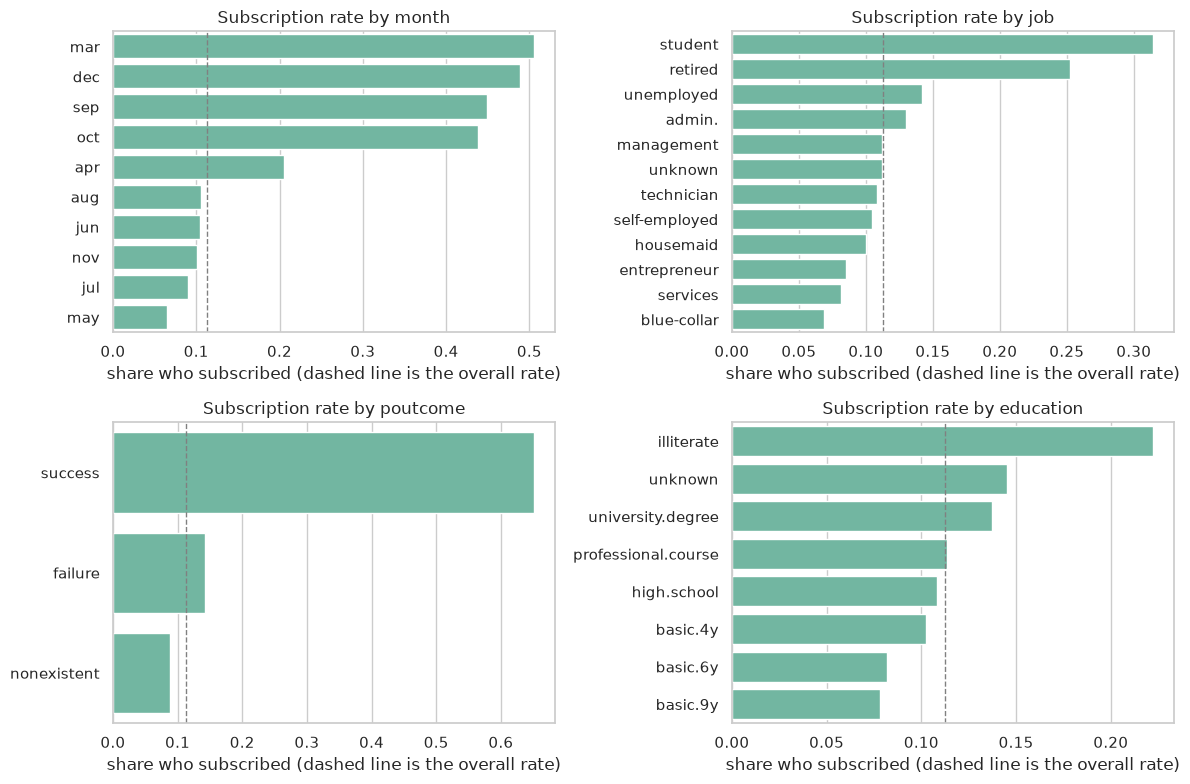

In [8]:
# Plotting the subscription rate for each level of four categorical variables
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), ["month", "job", "poutcome", "education"]):
    t = rate_table(col).reset_index()
    sns.barplot(data=t, y=col, x="rate", ax=ax, color="#66c2a5")
    ax.axvline(raw["y"].eq("yes").mean(), ls="--", c="grey", lw=1)
    ax.set_title(f"Subscription rate by {col}")
    ax.set_xlabel("share who subscribed (dashed line is the overall rate)"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

The patterns are strong and mostly make sense.

Customers who said yes in a previous campaign (`poutcome = success`) subscribed 65 percent of the time, roughly six times the overall rate. Past behaviour is a powerful signal.

Mobile phone contacts (`cellular`) converted at 14.7 percent against 5.2 percent for landlines.

The month effect is huge. May had the most calls (13,769) but the worst rate at 6.4 percent, while March, September, October and December convert at around 45 to 50 percent on just a few hundred calls each. This is less likely to be about the calendar and more about when the bank chose to call and what the economy was doing at the time, which ties into the time drift shown in section 1.7.

For `default`, the rate among customers with an `unknown` answer is 5.2 percent, less than half of the 12.9 percent among those who said "no". The fact that the answer is missing is itself informative, which argues for keeping `unknown` as a category rather than filling it in. Only 3 customers out of 41,188 admitted being in default, so this variable carries almost no information beyond the unknown flag.

Students and retired people subscribe most often, blue collar workers least often.

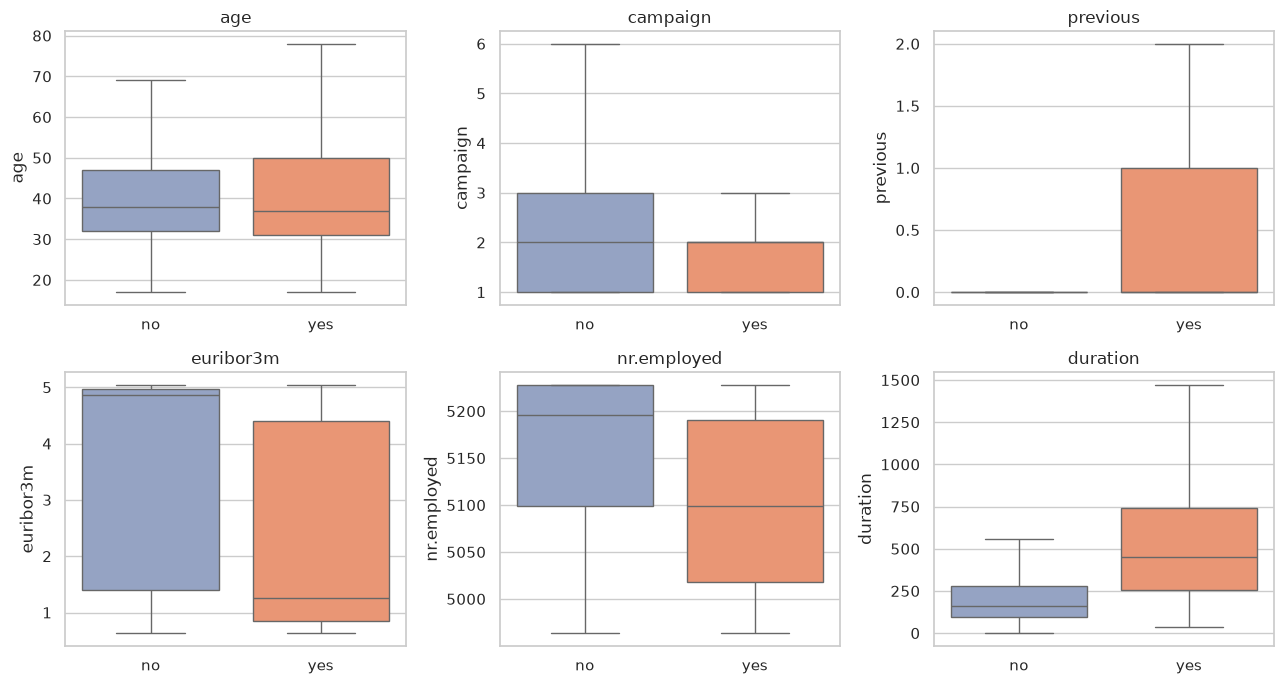

In [9]:
# Here I am comparing the numeric variables for subscribers and non subscribers (hiding outliers so the boxes stay readable)
show = ["age", "campaign", "previous", "euribor3m", "nr.employed", "duration"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), show):
    sns.boxplot(data=raw, x="y", y=col, ax=ax, palette=["#8da0cb", "#fc8d62"], showfliers=False)
    ax.set_title(col); ax.set_xlabel("")
plt.tight_layout(); plt.show()

Subscribers were called at lower Euribor rates and lower employment levels, which suggests customers were more willing to lock money away when the economy was weak. Age barely separates the two groups on the median, although the bar chart above shows the very young and the retired behave differently. The `duration` panel shows the largest gap of all: subscribers talked for much longer. That is exactly the problem with this variable. A long call is a consequence of a customer being interested, and the bank cannot know the length of a call it has not made yet.

### 1.6 Redundancy between the numeric inputs

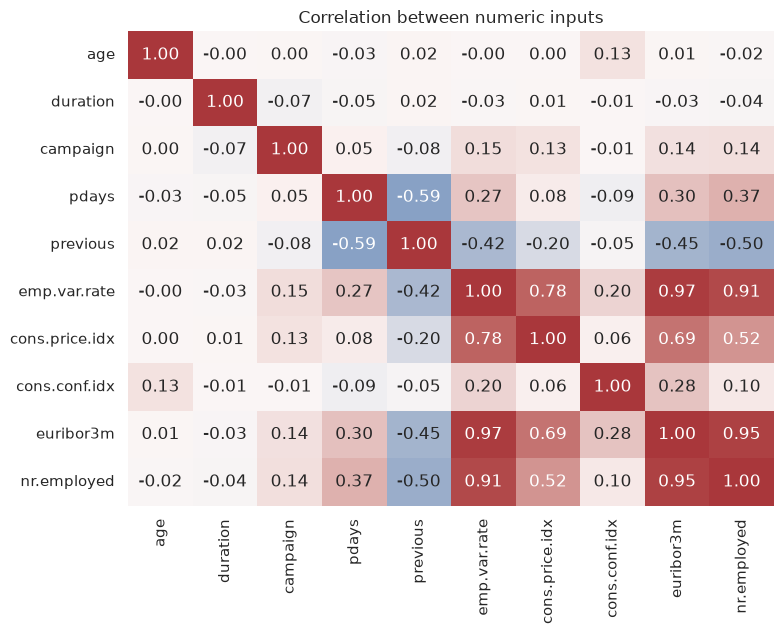

In [10]:
# Checking how strongly the numeric inputs are correlated with each other
corr = raw[num_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax, cbar=False)
ax.set_title("Correlation between numeric inputs")
plt.tight_layout(); plt.show()

The economic indicators are almost copies of each other. `euribor3m`, `emp.var.rate` and `nr.employed` correlate between 0.91 and 0.97. For tree based models this redundancy is harmless. For logistic regression it makes individual coefficients unstable, which is one reason the logistic model below uses L2 regularisation. I keep all five because together they describe the economic climate, but I do not try to interpret the logistic coefficients one by one.

### 1.7 The data is ordered in time, and the world changed

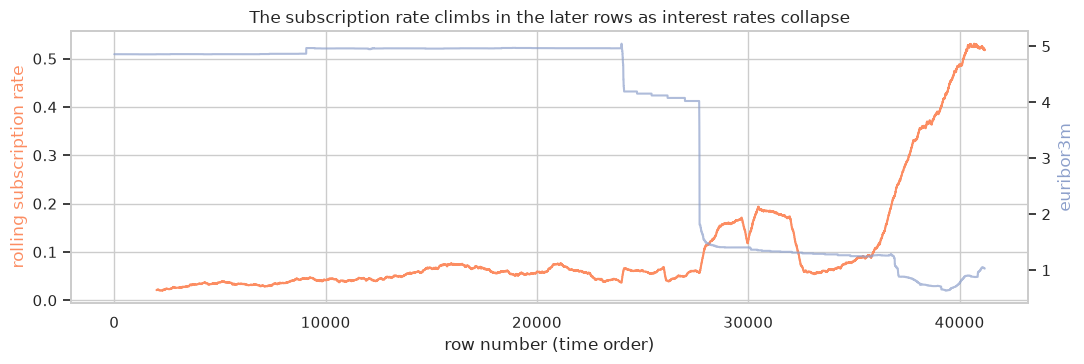

In [11]:
# The rows are stored in time order (May 2008 to November 2010), so I am plotting a rolling average of the
# subscription rate next to the Euribor rate to see how much conditions moved over that period
roll_rate = raw["y"].eq("yes").rolling(2000).mean()
fig, ax1 = plt.subplots(figsize=(11, 3.8))
ax1.plot(roll_rate.index, roll_rate, color="#fc8d62")
ax1.set_ylabel("rolling subscription rate", color="#fc8d62")
ax2 = ax1.twinx()
ax2.plot(raw.index, raw["euribor3m"], color="#8da0cb", alpha=0.7)
ax2.set_ylabel("euribor3m", color="#8da0cb"); ax2.grid(False)
ax1.set_xlabel("row number (time order)")
ax1.set_title("The subscription rate climbs in the later rows as interest rates collapse")
plt.tight_layout(); plt.show()

This chart is one of the most important findings of the exploration. The rows run from May 2008 to November 2010, covering the financial crisis. In the first three quarters of the file the subscription rate mostly sits between 5 and 13 percent. In the final quarter, after interest rates fell to below 1 percent, it climbs well above 30 percent. A model trained on the past will be used on the future, so I test the candidate models on a time ordered split as well as a random one (section 2.5). A random split alone would give an overly rosy picture.

In [12]:
# Seeing how often the 999 code appears in pdays and how it lines up with poutcome
print("Share of rows with pdays = 999 (never contacted before):", round((raw["pdays"] == 999).mean(), 4))
print(pd.crosstab(raw["pdays"] == 999, raw["poutcome"]).rename(index={True: "pdays is 999", False: "pdays is a real number"}))

Share of rows with pdays = 999 (never contacted before): 0.9632
poutcome                failure  nonexistent  success
pdays                                                
pdays is a real number      142            0     1373
pdays is 999               4110        35563        0


96 percent of customers have the 999 code. The cross table shows that `pdays` and `poutcome` largely repeat each other: everyone with `nonexistent` previous outcome also has 999. Note one oddity, 4,110 customers with a failed previous campaign still have 999 for `pdays`, so the two columns are not perfectly consistent. I keep `poutcome` and `previous`, and turn `pdays` into a simple flag.

### 1.8 Short report on the data

The dataset holds 41,188 telephone contacts with 20 inputs describing the customer (age, job, marital status, education, credit status, loans), the contact (phone type, month, weekday), the campaign history (number of calls, previous contacts, previous outcome) and the economy (five indicators). The target is rare at 11.3 percent.

Its main limitations are these. First, missing answers are hidden as `unknown`, and in `default` they cover a fifth of the rows. Second, `duration` leaks the outcome and cannot be used for a model meant to choose whom to call. Third, `pdays` uses a 999 code instead of a missing value. Fourth, the economic indicators are highly collinear. Fifth, and most important for deployment, the data spans a financial crisis and the subscription rate shifts strongly over time, so performance measured on a random split will overstate what the bank should expect next season. Finally, we only see customers the bank chose to call, so the model learns about that population and nobody else.

The strongest signals in the exploration are the outcome of a previous campaign, the type of phone, the month of the call and the economic indicators.

## Part 1 (continued). Data preparation

Each step below is taken for a stated reason.

1. I am dropping the 12 exact duplicate rows. A copy that lands in both training and test data would let the model be scored on something it has already seen.
2. I am dropping `duration`. The README says plainly that it is only known after the call, and including it is a textbook case of target leakage (Kaufman and colleagues, 2012). Section 2.6 shows how much it would inflate the scores.
3. I am replacing `pdays` with a yes or no flag, `prev_contacted`. The 999 code would otherwise be read as "a very long time ago", which is wrong, and 96 percent of rows carry it.
4. I am replacing `campaign` with `log(1 + campaign)`. This shrinks the long tail so a handful of customers called 40 or 50 times do not dominate the linear model. Trees are unaffected because the transform keeps the order.
5. I am keeping `unknown` as its own category instead of imputing it. The exploration showed that unknown answers behave differently from known ones (5.2 percent versus 12.9 percent subscription for `default`), so the missingness carries signal, and the README itself lists this as a valid option.
6. I am one hot encoding the categorical columns and, for logistic regression only, standardising the numeric columns. These transforms sit inside a scikit learn pipeline so that they are learned from training folds only.
7. I am holding out a stratified 20 percent test set that stays untouched until the final comparison.

In [13]:
# Working on a copy so the raw data stays untouched
df = raw.copy()

# Step 1: I am removing the exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Step 2: I am dropping duration because it is only known once the call has ended
df = df.drop(columns=["duration"])

# Step 3: I am swapping the 999 code in pdays for a clean yes or no flag
df["prev_contacted"] = (df["pdays"] != 999).astype(int)
df = df.drop(columns=["pdays"])

# Step 4: I am log transforming the skewed campaign count
df["campaign_log"] = np.log1p(df["campaign"])
df = df.drop(columns=["campaign"])

# Finally I am encoding the target as 1 for yes and 0 for no
df["y"] = (df["y"] == "yes").astype(int)

print("Prepared shape:", df.shape)
df.head()

Prepared shape: (41176, 20)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,prev_contacted,campaign_log
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,0.693147
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,0.693147
2,37,services,married,high.school,no,yes,no,telephone,may,mon,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,0.693147
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,0.693147
4,56,services,married,high.school,no,no,yes,telephone,may,mon,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,0.693147


In [14]:
# Separating the inputs from the target and splitting off a test set
X = df.drop(columns="y")
y = df["y"]

cat_features = X.select_dtypes(include=["object", "str"]).columns.tolist()
num_features = X.select_dtypes(include="number").columns.tolist()
print("Categorical inputs:", cat_features)
print("Numeric inputs:   ", num_features)

# Step 7: I am using a stratified split so the 11 percent subscription rate stays the same in both parts
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("\nTrain:", X_train.shape, "positive rate", round(y_train.mean(), 4))
print("Test: ", X_test.shape, "positive rate", round(y_test.mean(), 4))

Categorical inputs: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numeric inputs:    ['age', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'prev_contacted', 'campaign_log']

Train: (32940, 19) positive rate 0.1127
Test:  (8236, 19) positive rate 0.1127


In [15]:
# Steps 5 and 6: I am building one preprocessing recipe that every model shares, keeping "unknown" as its own category
def make_preprocessor(scale=True):
    num_step = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("num", num_step, num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
    ])

# I am setting up five fold stratified cross validation, which I reuse for tuning and for comparing models fold by fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

### 1.9 Majority class baseline

The simplest possible model predicts "no" for everyone. Its best probability guess for any customer is just the training subscription rate. Any model worth using has to beat this.

In [16]:
# Setting up the majority class baseline and a scoring helper I reuse for every model
def evaluate(y_true, prob, threshold=0.5):
    """Scoring a set of predicted probabilities with the metrics I use throughout the notebook."""
    pred = (prob >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "f1": f1_score(y_true, pred),
        "roc_auc": roc_auc_score(y_true, prob) if len(np.unique(prob)) > 1 else 0.5,
        "pr_auc": average_precision_score(y_true, prob),
        "brier": brier_score_loss(y_true, prob),
    }

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Baseline predicts:", np.unique(baseline.predict(X_test)))
base_prob = np.full(len(y_test), y_train.mean())   # the constant probability the baseline would give everyone
base_row = evaluate(y_test, base_prob)
pd.DataFrame([base_row], index=["majority class baseline"]).round(4)

Baseline predicts: [0]


,accuracy,precision,recall,f1,roc_auc,pr_auc,brier
majority class baseline,0.8873,0.0,0.0,0.0,0.5,0.1127,0.1


The baseline is 88.7 percent accurate and finds zero subscribers. Its PR AUC equals the subscription rate (0.113) and its ROC AUC is 0.5. Those are the numbers to beat. The accuracy figure is a good reminder of why accuracy alone would be misleading on this problem.

## Part 2. Selecting and ranking approaches

### 2.1 Why these three

I chose three approaches that represent different ideas about how the inputs relate to the outcome.

1. Logistic regression. A linear model on the log odds scale. It is the standard starting point for a yes or no outcome in marketing, it produces probabilities directly, and its behaviour is easy to explain. If it does nearly as well as the complex models, the bank should prefer it.
2. Random forest (Breiman, 2001). An average over hundreds of decision trees, each grown on a bootstrap sample. It picks up interactions (for example, phone type mattering more in some months) and nonlinear effects without being told about them, and the averaging makes it fairly resistant to overfitting.
3. Gradient boosting (Friedman, 2001), using scikit learn's histogram based version. Trees are added one at a time to correct the mistakes of the earlier ones. On tabular data like this it is often the most accurate method available.

Moro, Cortez and Rita (2014) compared logistic regression, decision trees, neural networks and support vector machines on this same problem, so these three cover the classic linear option and the two strongest tree ensembles. Each model gets a small hyper parameter grid, tuned with five fold cross validation on the training data only, choosing the setting with the best PR AUC.

In [17]:
# Defining the three candidate models with small tuning grids, then tuning each one on the training data only
candidates = {
    "Logistic regression": (
        Pipeline([("prep", make_preprocessor(scale=True)),
                  ("model", LogisticRegression(max_iter=2000))]),
        {"model__C": [0.01, 0.1, 1.0]},
    ),
    "Random forest": (
        Pipeline([("prep", make_preprocessor(scale=False)),
                  ("model", RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE))]),
        {"model__min_samples_leaf": [10, 30], "model__max_features": ["sqrt", 0.3]},
    ),
    "Gradient boosting": (
        Pipeline([("prep", make_preprocessor(scale=False)),
                  ("model", HistGradientBoostingClassifier(max_iter=300, random_state=RANDOM_STATE))]),
        {"model__learning_rate": [0.03, 0.1], "model__max_leaf_nodes": [15, 31]},
    ),
}

scoring = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "brier": "neg_brier_score"}
tuned, cv_rows, fold_scores = {}, [], {}
for name, (pipe, grid) in candidates.items():
    search = GridSearchCV(pipe, grid, scoring=scoring, refit="pr_auc", cv=cv, n_jobs=1)
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    i, res = search.best_index_, search.cv_results_
    fold_scores[name] = [res[f"split{k}_test_pr_auc"][i] for k in range(cv.n_splits)]
    print(f"{name:20s} best settings: {search.best_params_}")
    cv_rows.append({
        "model": name,
        "cv PR AUC mean": res["mean_test_pr_auc"][i], "cv PR AUC sd": res["std_test_pr_auc"][i],
        "cv ROC AUC mean": res["mean_test_roc_auc"][i], "cv ROC AUC sd": res["std_test_roc_auc"][i],
        "cv Brier": -res["mean_test_brier"][i],
    })
cv_table = pd.DataFrame(cv_rows).set_index("model")
cv_table.round(4)

Logistic regression  best settings: {'model__C': 1.0}


Random forest        best settings: {'model__max_features': 'sqrt', 'model__min_samples_leaf': 10}


Gradient boosting    best settings: {'model__learning_rate': 0.03, 'model__max_leaf_nodes': 15}


,cv PR AUC mean,cv PR AUC sd,cv ROC AUC mean,cv ROC AUC sd,cv Brier
model,,,,,
Logistic regression,0.451,0.0142,0.7890,0.0070,0.0787
Random forest,0.469,0.0150,0.7968,0.0097,0.0770
Gradient boosting,0.467,0.0165,0.8014,0.0085,0.0770


### 2.2 Cross validation results, fold by fold

Because every model was scored on exactly the same five folds, the differences can be compared fold by fold, which is a fairer test than comparing averages.

In [18]:
# Comparing the models fold by fold, since they were all scored on exactly the same folds
fold_df = pd.DataFrame(fold_scores, index=[f"fold {k+1}" for k in range(cv.n_splits)])
fold_df["RF minus GB"] = fold_df["Random forest"] - fold_df["Gradient boosting"]
fold_df["RF minus LR"] = fold_df["Random forest"] - fold_df["Logistic regression"]
fold_df["GB minus LR"] = fold_df["Gradient boosting"] - fold_df["Logistic regression"]
fold_df.round(4)

,Logistic regression,Random forest,Gradient boosting,RF minus GB,RF minus LR,GB minus LR
fold 1,0.4586,0.4712,0.4687,0.0025,0.0126,0.0101
fold 2,0.4505,0.4710,0.4771,-0.0061,0.0205,0.0266
fold 3,0.4242,0.4409,0.4355,0.0054,0.0168,0.0114
fold 4,0.4563,0.4860,0.4829,0.0031,0.0296,0.0265
fold 5,0.4654,0.4759,0.4705,0.0053,0.0105,0.0052


All three models clearly beat the baseline PR AUC of 0.113, reaching about 0.45 to 0.47, and ROC AUC near 0.79 to 0.80. Both tree ensembles beat logistic regression in every one of the five folds, by roughly 0.01 to 0.03. The random forest and gradient boosting are essentially tied: the forest is ahead in four folds out of five but only by a few thousandths.

### 2.3 The held out test set

In [19]:
# Scoring each tuned model on the held out test set, next to the baseline
test_prob = {name: m.predict_proba(X_test)[:, 1] for name, m in tuned.items()}
rows = {"Majority class baseline": base_row}
for name, p in test_prob.items():
    rows[name] = evaluate(y_test, p)
test_table = pd.DataFrame(rows).T
test_table.round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc,brier
Majority class baseline,0.8873,0.0000,0.0000,0.0000,0.5000,0.1127,0.1000
Logistic regression,0.8985,0.6544,0.2101,0.3181,0.8003,0.4540,0.0778
Random forest,0.9006,0.6698,0.2317,0.3443,0.8077,0.4867,0.0753
Gradient boosting,0.9014,0.6758,0.2403,0.3545,0.8139,0.4950,0.0750


In [20]:
# I am bootstrapping the test set 1,000 times to put uncertainty bands around PR AUC and around the gaps between models
rng = np.random.default_rng(RANDOM_STATE)
names = list(test_prob)
yt = y_test.to_numpy()
boot = {n: [] for n in names}
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    for n in names:
        boot[n].append(average_precision_score(yt[idx], test_prob[n][idx]))
boot = pd.DataFrame(boot)

ci = pd.DataFrame({"PR AUC": [average_precision_score(yt, test_prob[n]) for n in names],
                   "lower 2.5%": boot.quantile(0.025), "upper 97.5%": boot.quantile(0.975)}, index=names)
print(ci.round(4))

pairs = [("Gradient boosting", "Random forest"), ("Random forest", "Logistic regression"),
         ("Gradient boosting", "Logistic regression")]
diff = pd.DataFrame({f"{a} minus {b}": boot[a] - boot[b] for a, b in pairs})
print("\nBootstrap distribution of the PR AUC difference")
print(pd.DataFrame({"mean": diff.mean(), "lower 2.5%": diff.quantile(0.025),
                    "upper 97.5%": diff.quantile(0.975), "share above zero": (diff > 0).mean()}).round(4))

                     PR AUC  lower 2.5%  upper 97.5%
Logistic regression  0.4540      0.4199       0.4917
Random forest        0.4867      0.4521       0.5214
Gradient boosting    0.4950      0.4613       0.5303

Bootstrap distribution of the PR AUC difference
                                               mean  lower 2.5%  upper 97.5%  share above zero
Gradient boosting minus Random forest        0.0082      0.0006       0.0165             0.977
Random forest minus Logistic regression      0.0326      0.0191       0.0457             1.000
Gradient boosting minus Logistic regression  0.0408      0.0283       0.0542             1.000


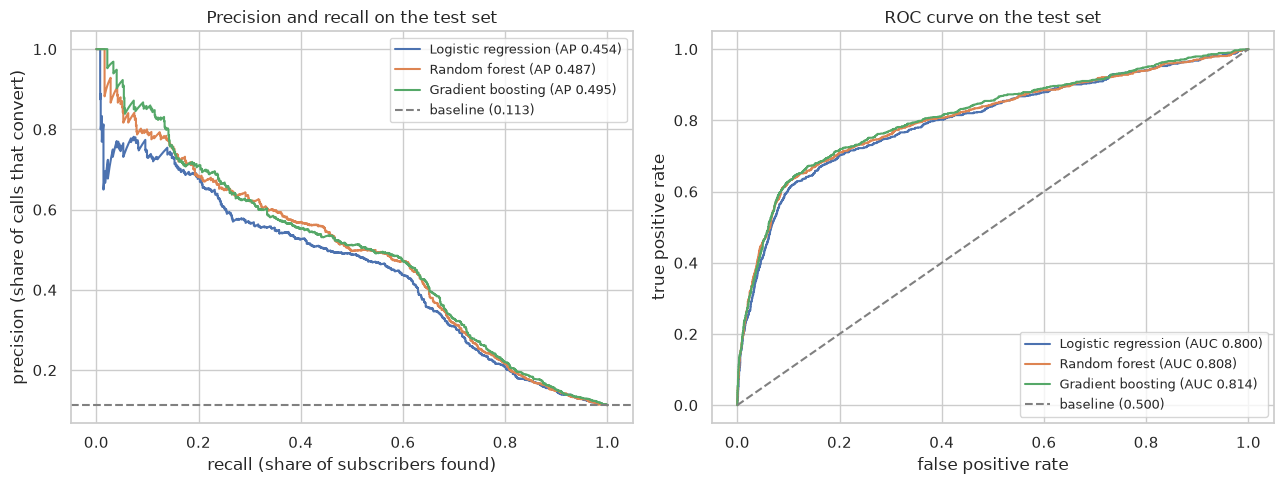

In [21]:
# Drawing the precision recall and ROC curves for all three models
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for n, p in test_prob.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(rec, prec, label=f"{n} (AP {average_precision_score(y_test, p):.3f})")
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(y_test, p):.3f})")
axes[0].axhline(y_test.mean(), ls="--", c="grey", label=f"baseline ({y_test.mean():.3f})")
axes[0].set(xlabel="recall (share of subscribers found)", ylabel="precision (share of calls that convert)",
            title="Precision and recall on the test set")
axes[1].plot([0, 1], [0, 1], ls="--", c="grey", label="baseline (0.500)")
axes[1].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve on the test set")
for ax in axes:
    ax.legend(loc="best", fontsize=9)
plt.tight_layout(); plt.show()

On the test set the ordering is gradient boosting (PR AUC 0.495), random forest (0.487), then logistic regression (0.454). The bootstrap tells us how much to trust that ordering. Both ensembles beat logistic regression in every one of the 1,000 resamples, so that gap is real. The gap between gradient boosting and the random forest is only about 0.008, which is smaller than the fold to fold spread seen in cross validation, where the order was actually the other way round. On a random split, the two ensembles are tied for practical purposes.

Note also that at the default threshold of 0.5 every model finds fewer than a quarter of subscribers. That is a strong hint that 0.5 is the wrong threshold for this problem, which Part 3 deals with.

### 2.4 Calibration and lift

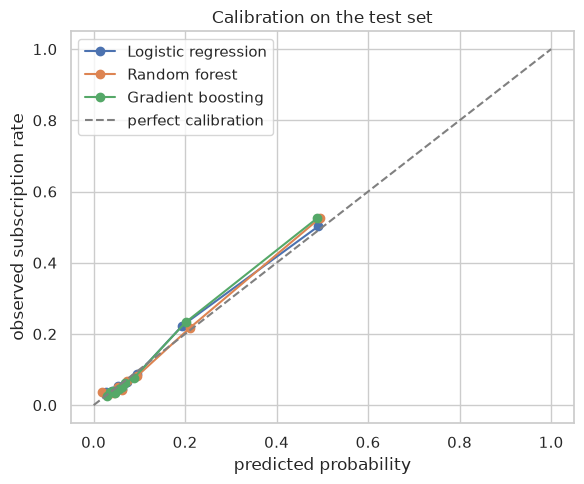

In [22]:
# Checking calibration, that is, whether a predicted 30 percent really means about 30 percent subscribe
fig, ax = plt.subplots(figsize=(6, 5))
for n, p in test_prob.items():
    frac, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", label=n)
ax.plot([0, 1], [0, 1], ls="--", c="grey", label="perfect calibration")
ax.set(xlabel="predicted probability", ylabel="observed subscription rate", title="Calibration on the test set")
ax.legend(); plt.tight_layout(); plt.show()

The above plot checks whether the predicted probabilities can be taken at face value. If a model says a group of customers has a 20 percent chance of subscribing, then about 20 percent of them should actually subscribe. Points on the dashed diagonal mean perfect calibration.

All three models sit very close to the diagonal, which tells me their probabilities are trustworthy.

**Most points are bunched below 0.1.** I used ten bins with equal numbers of customers. Since only about 11 percent of people subscribe, most customers get low scores, and eight of the ten bins fall in that narrow range. Down there, predicted and observed rates match almost exactly.

**In the middle**, customers given about a 20 percent chance subscribed at about 21 to 23 percent, which is a very close match.

**At the top end**, the highest scoring tenth of customers were given about a 49 percent chance on average and subscribed at about 50 to 53 percent. The models are very slightly cautious here, underestimating the best prospects by a couple of percentage points, but the gap is small.

The three models are almost indistinguishable on calibration, so this plot does not change the ranking. It does matter for the threshold decision, though. The rule of calling anyone whose probability exceeds the cost of a call relative to the value of a subscription only works if the probabilities are honest, and this plot shows that they are. The Brier scores (about 0.075 to 0.078, against 0.100 for the baseline) point the same way.

In [23]:
# Here I am checking what share of subscribers the bank would reach if it only called the top 10, 20 or 30 percent of customers by score
def capture_curve(y_true, prob):
    order = np.argsort(-prob)
    hits = np.cumsum(np.asarray(y_true)[order])
    return np.arange(1, len(prob) + 1) / len(prob), hits / hits[-1]

lift_rows = []
for n, p in test_prob.items():
    s, c = capture_curve(y_test, p)
    for top in [0.1, 0.2, 0.3]:
        k = int(top * len(s)) - 1
        lift_rows.append({"model": n, "top share called": f"top {int(top*100)}%", "captured": c[k]})
pd.DataFrame(lift_rows).pivot(index="model", columns="top share called", values="captured").round(3)

top share called,top 10%,top 20%,top 30%
model,,,
Gradient boosting,0.467,0.672,0.740
Logistic regression,0.446,0.644,0.722
Random forest,0.467,0.659,0.732


All three models are reasonably well calibrated: points sit close to the diagonal, with the Brier scores (about 0.075 to 0.078) well below the baseline's 0.100. Good calibration matters because Part 3 uses the probabilities to reason about costs.

The lift table shows what the models are worth in plain terms. Calling only the top 10 percent of customers chosen by any of the models reaches about 45 to 47 percent of all subscribers, against 10 percent for calling at random. Calling the top 30 percent reaches roughly 72 to 74 percent.

### 2.5 Robustness check: predicting forward in time

Section 1.7 showed that conditions changed a lot over the 30 months. In real use the bank trains on past campaigns and scores customers for the next one. To imitate this, I use an expanding window: train on the earliest part of the data and test on the next block, five times, with each training window growing. Each model keeps the settings it was tuned with above.

In [24]:
# Training on earlier calls and testing on the next block, five times, to see how each model copes with time drift
tss = TimeSeriesSplit(n_splits=5)
time_rows = []
for k, (tr, te) in enumerate(tss.split(X)):
    row = {"window": k + 1, "train rows": len(tr), "test rows": len(te),
           "test positive rate (random guess PR AUC)": y.iloc[te].mean()}
    for n, m in tuned.items():
        p = clone(m).fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[te])[:, 1]
        row[n] = average_precision_score(y.iloc[te], p)
    time_rows.append(row)
time_df = pd.DataFrame(time_rows).set_index("window")
time_df.round(3)

,train rows,test rows,test positive rate (random guess PR AUC),Logistic regression,Random forest,Gradient boosting
window,,,,,,
1,6866,6862,0.046,0.049,0.043,0.046
2,13728,6862,0.065,0.071,0.068,0.074
3,20590,6862,0.053,0.051,0.043,0.052
4,27452,6862,0.127,0.198,0.220,0.147
5,34314,6862,0.355,0.538,0.551,0.472


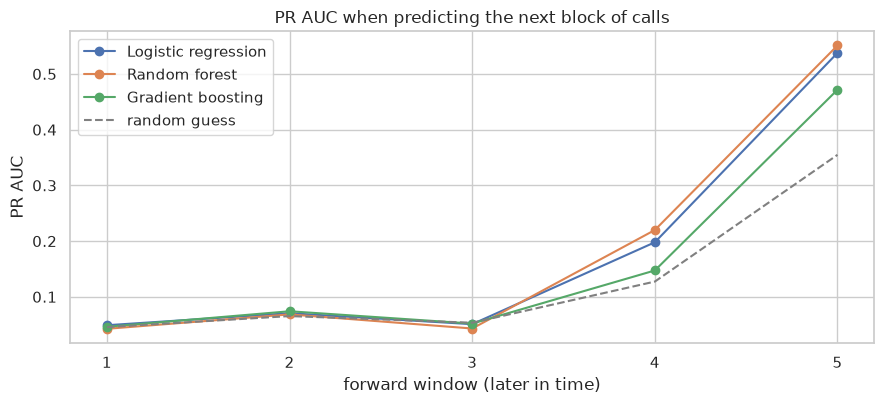

In [25]:
# Plotting the forward in time results
fig, ax = plt.subplots(figsize=(9, 4.2))
for n in tuned:
    ax.plot(time_df.index, time_df[n], marker="o", label=n)
ax.plot(time_df.index, time_df["test positive rate (random guess PR AUC)"], ls="--", c="grey", label="random guess")
ax.set(xlabel="forward window (later in time)", ylabel="PR AUC", title="PR AUC when predicting the next block of calls")
ax.set_xticks(time_df.index); ax.legend(); plt.tight_layout(); plt.show()

This is the most revealing test in the notebook, and it changes the picture.

In the first three windows (the calm, low conversion period of 2008 and 2009) none of the models does much better than a random guess. They are learning from a world where almost nobody subscribed.

In windows 4 and 5, when the subscription rate jumps, the models do find signal, but they react differently to conditions they have not seen before. The random forest is the best of the three in both of these windows. Gradient boosting, which had a slight edge on the random split, now falls clearly behind both other models, for example about 0.47 against 0.54 to 0.55 in window 5. My reading is that boosting fits the training period more tightly, including its specific economic values, and so transfers less well when interest rates move outside the range it learned from. Logistic regression sits close to the forest here.

Two lessons follow. First, every model will perform worse in practice than the random split suggests, and the bank should expect to retrain regularly. Second, the random forest is the most dependable choice because it is at or near the top in every test we have run.

### 2.6 Sensitivity check: what if `duration` had been kept?

In [26]:
# I am rebuilding the inputs with duration added back, keeping the same rows and the same split, to see how much it inflates the scores
X_dur = raw.drop_duplicates().reset_index(drop=True)[["duration"]].join(X)
Xd_tr, Xd_te = X_dur.loc[X_train.index], X_dur.loc[X_test.index]
leaky = Pipeline([
    ("prep", ColumnTransformer([("num", "passthrough", num_features + ["duration"]),
                                ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features)])),
    ("model", clone(tuned["Random forest"].named_steps["model"]))])
leaky.fit(Xd_tr, y_train)
p_leak = leaky.predict_proba(Xd_te)[:, 1]
p_rf = test_prob["Random forest"]
pd.DataFrame({"PR AUC": [average_precision_score(y_test, p_leak), average_precision_score(y_test, p_rf)],
              "ROC AUC": [roc_auc_score(y_test, p_leak), roc_auc_score(y_test, p_rf)]},
             index=["Random forest WITH duration (leaky)", "Random forest without duration"]).round(4)

,PR AUC,ROC AUC
Random forest WITH duration (leaky),0.6685,0.9477
Random forest without duration,0.4867,0.8077


Adding `duration` back lifts ROC AUC from about 0.81 to about 0.95 and PR AUC from about 0.49 to about 0.67. Those numbers look impressive, and a reader who did not know the data might report them. But the model would be useless for its purpose, because call length is only known after the call has happened. This check confirms that dropping the column was necessary and that the honest performance level is the lower one.

### 2.7 What drives the chosen model?

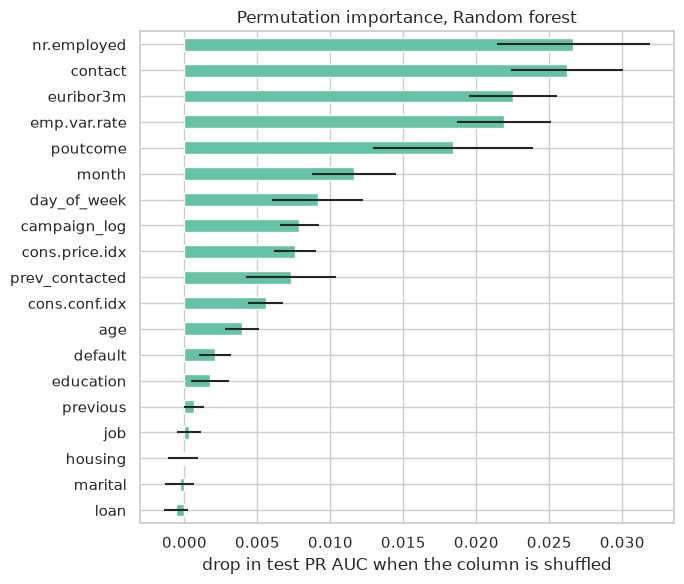

In [27]:
# Measuring which inputs the random forest relies on, by shuffling each column and seeing how much PR AUC drops
best_name = "Random forest"
best = tuned[best_name]
pi = permutation_importance(best, X_test, y_test, scoring="average_precision", n_repeats=5,
                            random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
err = pd.Series(pi.importances_std, index=X_test.columns)[imp.index]
fig, ax = plt.subplots(figsize=(7, 6))
imp.plot.barh(ax=ax, color="#66c2a5", xerr=err)
ax.set(title=f"Permutation importance, {best_name}", xlabel="drop in test PR AUC when the column is shuffled")
plt.tight_layout(); plt.show()

Shuffling the number employed (`nr.employed`) does the most damage, closely followed by the type of phone (`contact`), the Euribor rate, the employment variation rate and the outcome of the previous campaign. Month comes next. At the other end, housing loan, personal loan, marital status and job add almost nothing once the other inputs are known. This agrees with the exploration. It also explains the time drift problem: the model leans heavily on the state of the economy, and that state changes. Permutation importance on correlated inputs should be read with care, because when one of several near identical columns is shuffled, the others can partly cover for it. These importances describe what the model uses, not what causes a customer to subscribe.

### 2.8 Ranking and justification

In [28]:
# Gathering the main evidence for the ranking into one table
summary = pd.DataFrame({
    "CV PR AUC (random folds)": cv_table["cv PR AUC mean"],
    "Test PR AUC": ci["PR AUC"],
    "Test ROC AUC": test_table.loc[names, "roc_auc"],
    "Test Brier": test_table.loc[names, "brier"],
    "Mean PR AUC, forward windows 4 and 5": time_df.loc[[4, 5], names].mean(),
}).loc[["Random forest", "Gradient boosting", "Logistic regression"]]
summary.insert(0, "Rank", [1, 2, 3])
summary.round(4)

,Rank,CV PR AUC (random folds),Test PR AUC,Test ROC AUC,Test Brier,"Mean PR AUC, forward windows 4 and 5"
Random forest,1,0.469,0.4867,0.8077,0.0753,0.3855
Gradient boosting,2,0.467,0.4950,0.8139,0.0750,0.3095
Logistic regression,3,0.451,0.4540,0.8003,0.0778,0.3679


Final ranking.

1. Random forest. It was ahead in four of five cross validation folds, within 0.008 PR AUC of the best model on the random test set, and the best model when predicting forward in time in the windows where there is signal. It is well calibrated and needs little tuning. It wins on consistency across every piece of evidence.
2. Gradient boosting. It scored highest on the random test set, but its lead over the forest is inside the noise, and it fell clearly behind when predicting forward in time. Because the bank will always be predicting the future from the past, that weakness is the deciding factor against putting it first. It remains a strong option if it is retrained often.
3. Logistic regression. It is reliably about 0.03 to 0.04 PR AUC behind the ensembles on random splits, a gap the bootstrap confirms is real. It held up well under time drift and is the easiest to explain, so it is a sensible fallback where transparency matters more than the last few points of performance.

Note that the second and third places are close and depend on how much weight one gives to the forward in time test versus the random split. I placed gradient boosting second because it clearly beat logistic regression on the random split and in the cross validation folds, while the forward test is based on only two informative windows.

## Part 3. Choosing a decision threshold

### 3.1 The trade off

A model gives each customer a probability of subscribing. The bank calls everyone above some threshold. Lowering the threshold means more calls, which finds more subscribers (fewer missed sales) but also wastes more calls on people who say no. Raising it saves calls but misses customers who would have said yes. The default threshold of 0.5 has no special meaning here. With an 11 percent base rate it is far too strict, as section 2.3 showed.

To avoid tuning the threshold on the test set, I generate out of fold predictions for the training data with five fold cross validation, choose the threshold there, and only then check it on the test set.

In [29]:
# Getting out of fold predictions on the training data so I can choose a threshold without touching the test set
oof = cross_val_predict(clone(best), X_train, y_train, cv=cv, method="predict_proba")[:, 1]

def threshold_table(y_true, prob, thresholds):
    """For each threshold, counting the calls made, subscribers found, wasted calls and missed subscribers."""
    y_true = np.asarray(y_true)
    out = []
    for t in thresholds:
        pred = prob >= t
        tp = int((pred & (y_true == 1)).sum())
        fp = int((pred & (y_true == 0)).sum())
        fn = int((~pred & (y_true == 1)).sum())
        out.append({"threshold": t, "share called": pred.mean(), "calls": int(pred.sum()),
                    "subscribers found": tp, "unnecessary calls": fp, "missed subscribers": fn,
                    "precision": tp / max(tp + fp, 1), "recall": tp / (tp + fn)})
    return pd.DataFrame(out)

thr_grid = np.round(np.arange(0.02, 0.81, 0.01), 2)
oof_tab = threshold_table(y_train, oof, thr_grid)
oof_tab["f1"] = 2 * oof_tab.precision * oof_tab.recall / (oof_tab.precision + oof_tab.recall)
oof_tab[oof_tab.threshold.isin([0.05, 0.08, 0.10, 0.12, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50])].round(3)

,threshold,share called,calls,subscribers found,unnecessary calls,missed subscribers,precision,recall,f1
3,0.05,0.588,19366,3172,16194,539,0.164,0.855,0.275
6,0.08,0.313,10321,2668,7653,1043,0.259,0.719,0.380
8,0.10,0.232,7636,2456,5180,1255,0.322,0.662,0.433
10,0.12,0.194,6383,2350,4033,1361,0.368,0.633,0.466
13,0.15,0.168,5530,2254,3276,1457,0.408,0.607,0.488
18,0.20,0.151,4983,2175,2808,1536,0.436,0.586,0.500
23,0.25,0.138,4532,2057,2475,1654,0.454,0.554,0.499
28,0.30,0.117,3853,1855,1998,1856,0.481,0.500,0.490
38,0.40,0.066,2181,1280,901,2431,0.587,0.345,0.434
48,0.50,0.040,1309,869,440,2842,0.664,0.234,0.346


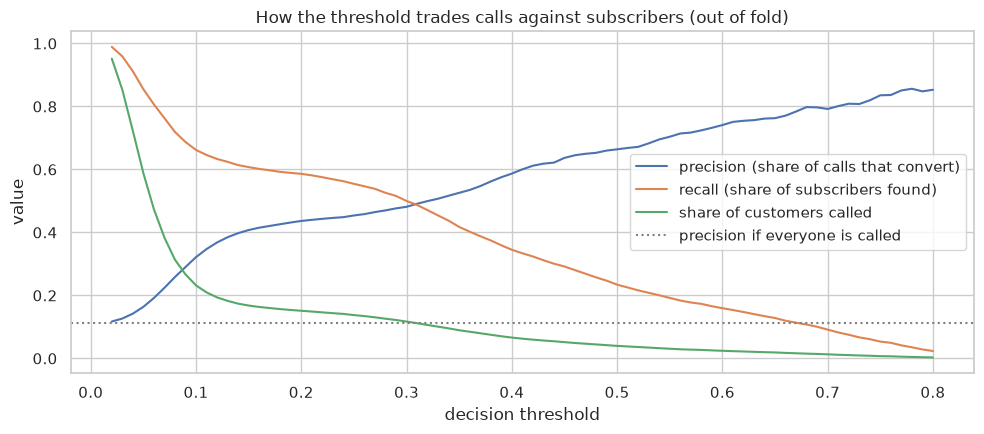

In [30]:
# Plotting how precision, recall and the share of customers called change as the threshold moves
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(oof_tab.threshold, oof_tab.precision, label="precision (share of calls that convert)")
ax.plot(oof_tab.threshold, oof_tab.recall, label="recall (share of subscribers found)")
ax.plot(oof_tab.threshold, oof_tab["share called"], label="share of customers called")
ax.axhline(y_train.mean(), ls=":", c="grey", label="precision if everyone is called")
ax.set(xlabel="decision threshold", ylabel="value", title="How the threshold trades calls against subscribers (out of fold)")
ax.legend(); plt.tight_layout(); plt.show()

This plot shows how my choice of threshold changes three things at once, using out of fold predictions on the training data so that the test set stays untouched.

**At very low thresholds** (below about 0.05), the model calls almost everyone. Recall is close to 1, so nearly every subscriber is found, but precision barely rises above the dotted line. In other words, it is hardly better than phoning the whole list.

**Between about 0.05 and 0.10**, the share of customers called falls steeply, from over 90 percent to roughly 23 percent, while recall only drops to about 0.66. This is where the model earns its keep: most of the wasted calls disappear while most subscribers are still found. Precision rises to about 0.32, nearly three times the 0.11 I would get by calling everyone.

**Between about 0.10 and 0.25**, the curves flatten. Recall drifts slowly down from about 0.66 to 0.56, and the share called shrinks only gently. Small changes to the threshold in this range make little practical difference.

**Above about 0.30**, recall starts falling quickly, so many real subscribers are missed. Precision keeps rising and reaches about 0.66 at the default threshold of 0.5, but by then fewer than a quarter of subscribers are being found. Precision and recall cross at roughly 0.3, where each is about 0.49.

The plot makes the trade off clear. Lowering the threshold finds more subscribers at the cost of more unnecessary calls, and raising it saves calls but misses sales. The elbow around 0.10 gives the best balance, which is why I recommend a threshold in the 0.10 to 0.15 range rather than the default 0.5.

### 3.2 Putting a price on the trade off

The data does not include costs, so I make the assumption explicit. Say a call costs 1 unit (staff time plus the goodwill lost by bothering someone) and a new subscription is worth V units to the bank. Then

net value = V times (subscribers found), minus (number of calls made).

Cost sensitive learning theory (Elkan, 2001) says that with well calibrated probabilities, the threshold that maximises this is 1 / V: call anyone whose chance of subscribing is worth more than the cost of the call. The table checks that rule against the actual out of fold results for several values of V.

In [31]:
# Working out the threshold that gives the best net value for several assumed values of a subscription
value_rows = []
for V in [5, 8, 10, 15, 20]:
    net = V * oof_tab["subscribers found"] - oof_tab["calls"]
    i = net.idxmax()
    value_rows.append({"V (value of a subscription in call costs)": V,
                       "best threshold found": oof_tab.threshold[i], "theory says 1/V": round(1 / V, 3),
                       "share called": oof_tab["share called"][i],
                       "recall": oof_tab.recall[i], "precision": oof_tab.precision[i]})
value_df = pd.DataFrame(value_rows)
value_df.round(3)

,V (value of a subscription in call costs),best threshold found,theory says 1/V,share called,recall,precision
0,5,0.20,0.200,0.151,0.586,0.436
1,8,0.13,0.125,0.183,0.624,0.385
2,10,0.13,0.100,0.183,0.624,0.385
3,15,0.07,0.067,0.383,0.763,0.224
4,20,0.06,0.050,0.474,0.807,0.192


In [32]:
# Looking at the threshold that maximises F1, for comparison
print("Threshold with the best F1 score (out of fold):", oof_tab.loc[oof_tab.f1.idxmax(), "threshold"])

Threshold with the best F1 score (out of fold): 0.21


In [33]:
# Here I am checking how flat the net value curve is around its best point when V = 10
flat = oof_tab[oof_tab.threshold.between(0.08, 0.20)][["threshold", "calls", "subscribers found"]].copy()
flat["net value (V = 10)"] = 10 * flat["subscribers found"] - flat["calls"]
flat["share of best"] = flat["net value (V = 10)"] / flat["net value (V = 10)"].max()
flat.round(3)

,threshold,calls,subscribers found,net value (V = 10),share of best
6,0.08,10321,2668,16359,0.954
7,0.09,8789,2550,16711,0.975
8,0.10,7636,2456,16924,0.987
9,0.11,6903,2397,17067,0.996
10,0.12,6383,2350,17117,0.999
11,0.13,6018,2316,17142,1.000
12,0.14,5728,2278,17052,0.995
13,0.15,5530,2254,17010,0.992
14,0.16,5380,2233,16950,0.989
15,0.17,5268,2216,16892,0.985


The best threshold found in the data lands within about 0.03 of the 1 / V rule in every case, which is further evidence that the forest's probabilities can be trusted. The more a subscription is worth relative to a call, the lower the threshold should be.

The net value curve is also quite flat near its peak. The table just above shows that for V = 10, every threshold between 0.10 and 0.15 earns within about 1.5 percent of the best value, so small changes in this range matter much less than getting away from 0.5.

### 3.3 Checking candidate thresholds on the untouched test set

In [34]:
# Now checking the candidate thresholds once on the untouched test set, against calling everyone
cands = [0.08, 0.10, 0.13, 0.15, 0.20, 0.30, 0.50]
test_thr = threshold_table(y_test, test_prob[best_name], cands)
everyone = pd.DataFrame([{"threshold": "call everyone", "share called": 1.0, "calls": len(y_test),
                          "subscribers found": int(y_test.sum()), "unnecessary calls": int((y_test == 0).sum()),
                          "missed subscribers": 0, "precision": y_test.mean(), "recall": 1.0}])
pd.concat([everyone, test_thr], ignore_index=True).round(3)

,threshold,share called,calls,subscribers found,unnecessary calls,missed subscribers,precision,recall
0,call everyone,1.000,8236,928,7308,0,0.113,1.000
1,0.08,0.306,2522,683,1839,245,0.271,0.736
2,0.1,0.231,1901,637,1264,291,0.335,0.686
3,0.13,0.184,1512,604,908,324,0.399,0.651
4,0.15,0.168,1384,590,794,338,0.426,0.636
5,0.2,0.150,1232,569,663,359,0.462,0.613
6,0.3,0.115,950,474,476,454,0.499,0.511
7,0.5,0.039,321,215,106,713,0.670,0.232


### 3.4 Recommendation

I recommend a threshold of 0.10 for the random forest, with a sensible working range between 0.10 and 0.15.

The reasoning is this. A term deposit typically ties up money for months and is worth far more to a bank than the cost of a few minutes on the phone, so V of 10 or more is a reasonable assumption, and 1 / 10 = 0.10. The out of fold optimum for V = 10 was 0.13, but as shown above the value curve is flat between 0.10 and 0.15, and I lean to the lower end because a missed subscriber is lost revenue while an extra call is cheap. On the untouched test set, a threshold of 0.10 means calling 23 percent of customers. Those calls find 69 percent of all subscribers, and about one in three calls converts (precision 0.335), which is roughly three times better than calling everyone (one in nine).

Put in terms of the trade off the bank cares about: compared with phoning every customer, a threshold of 0.10 cuts the number of calls by 77 percent and gives up 31 percent of the subscribers. Moving up to 0.15 or 0.20 saves another 500 to 670 calls on this test set and raises precision to over 0.4, but misses 36 to 39 percent of subscribers. Moving down to 0.08 finds 46 more subscribers at the price of 575 extra unnecessary calls, which is only worth it if a subscription is worth more than about 12 calls. The default of 0.5 would miss about three quarters of subscribers and should not be used.

If the bank's real value per subscription is different, the threshold should move with it, following the 1 / V rule from the table in section 3.2. If calls are cheap and subscriptions valuable (V near 20), go lower. If the call centre has little capacity or customers are irritated by calls (V near 5), go up towards 0.2.

Two cautions keep this recommendation proportionate. First, the forward in time test showed that conditions shift, so the share of customers above any fixed threshold will drift with the economy. The threshold should be reviewed and the model retrained before each campaign, and its calibration checked on recent calls. Second, the model predicts who tends to subscribe among the customers the bank chose to call. It does not show that calling a given person causes them to subscribe.

## References

Breiman, L. (2001). Random forests. Machine Learning, 45(1), 5 to 32.

Elkan, C. (2001). The foundations of cost sensitive learning. Proceedings of the 17th International Joint Conference on Artificial Intelligence, 973 to 978.

Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. Annals of Statistics, 29(5), 1189 to 1232.

Kaufman, S., Rosset, S., Perlich, C. and Stitelman, O. (2012). Leakage in data mining: formulation, detection, and avoidance. ACM Transactions on Knowledge Discovery from Data, 6(4), article 15.

Moro, S., Cortez, P. and Rita, P. (2014). A data driven approach to predict the success of bank telemarketing. Decision Support Systems, 62, 22 to 31.

Pedregosa, F. and colleagues (2011). Scikit learn: machine learning in Python. Journal of Machine Learning Research, 12, 2825 to 2830.

Saito, T. and Rehmsmeier, M. (2015). The precision recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. PLOS ONE, 10(3), e0118432.

Dataset: Bank Marketing data set, UCI Machine Learning Repository, provided with the assignment as `bank-additional-full.csv`.